# 1 · Static methods (the baseline)

Before training anything, measure the extrapolators that need **no model**: show the
newest frame again, continue the change in brightness, or continue the motion.

They set the bar on two sides:

- **quality** - a learned model has to score higher than the best of them *on the samples
  where something changed*. Over every sample, repeating the newest frame is close to
  perfect on a desktop, and every method looks good;
- **speed** - a guess is only worth drawing if it is ready before the frame it stands in
  for would have been, so it has the frame time (33 ms at 30 fps) minus decoding and drawing.

At the end, the three ONNX can express as plain arithmetic are exported for the client.

Needs: `00_data_preprocess.ipynb`. Results: `summary.md`, "Static methods".

In [1]:
"""Settings and data."""

import matplotlib.pyplot as plt
import numpy as np
import torch

from helpers import metrics, models, runs, speed, training, webexport
from helpers.training import DATA_DIR, DEVICE

CONTEXT, AHEAD = 2, 1     # the client's contract: previous and current in, the frame after out
BENCH_SIZES = [(640, 360), (960, 540), (1280, 720), (1920, 1080)]   # stream frames
SEED = 0

manifest = training.load_manifest()
training.describe(manifest)
HALO = manifest["halo"]

# every validation run at its fixed sample: (previous, current), and the frame after
inputs, targets = runs.load(DATA_DIR, "val", manifest, CONTEXT, AHEAD)
masks = runs.groups(manifest, "val", inputs[:, -1], targets, HALO)
KINDS = [kind for kind in ("page", "desktop", "photo", "video", "cursor") if kind in masks]
for kind in KINDS:
    masks[f"{kind}, changed"] = masks[kind] & masks["changed"]
print("val    ", inputs.shape, "->", targets.shape)
print("samples", {name: int(mask.sum()) for name, mask in masks.items() if "," not in name})

device  cuda NVIDIA GeForce RTX 3090
stream  x2 down from a 1280x720 window, 30 fps
run     96 px (64 px + a halo of 16), 8 frames each


val     (3226, 2, 96, 96, 3) -> (3226, 96, 96, 3)
samples {'all': 3226, 'changed': 1852, 'unchanged': 1374, 'cursor': 170, 'page': 780, 'desktop': 461, 'video': 1585, 'photo': 400}


## The methods

- **repeat** shows the newest frame again: what a client does through a stall today, and
  what every other method has to beat;
- **linear** continues each pixel's change in brightness, `current + (current - previous)`:
  the mock graph the client runs now. It is right for a fade and wrong wherever something
  moves - a moved edge is drawn twice, once too dark and once too light;
- **half step** goes half as far, `current + (current - previous) / 2`: between the two;
- **shift** continues the *motion* instead: it finds the whole-pixel offset that carries
  `previous` onto `current` best (luma L1, searching every offset within the radius) and
  moves `current` by it once more. For the **tile** there is one offset for the whole
  picture - right for a scroll or a pan and for nothing else; with **blocks**, each 16 or 8
  pixel block finds its own, which can follow a cursor or a dragged window but also finds
  false matches in repeating text.

The shift methods search as far as the halo: content that moved further came from outside
the tile, and no method that sees only the tile can know what it was.

In [2]:
"""The methods, and their quality on every validation sample, by group."""

METHODS = {
    "repeat": models.Repeat(),
    "linear": models.Blend(1.0),
    "half step": models.Blend(0.5),
    "shift, tile": models.Shift(radius=HALO, block=None),
    "shift, 16 px blocks": models.Shift(radius=HALO, block=16),
    "shift, 8 px blocks": models.Shift(radius=HALO, block=8),
}

results = {name: training.evaluate(method.to(DEVICE), inputs, targets, masks, trim=HALO)
           for name, method in METHODS.items()}

for group in ("changed", "all", "unchanged"):
    print(f"\n{group}: {masks[group].sum()} samples")
    metrics.print_table({name: scores[group] for name, scores in results.items()},
                        extra=lambda name, s, g=group: f"   {s['wpsnr'] - results['repeat'][g]['wpsnr']:+6.2f} dB vs repeat")


changed: 1852 samples
                         wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
repeat                   27.21    26.05    56.33    57.33     25.69   0.7312    +0.00 dB vs repeat
linear                   24.74    23.59    53.48    54.36     23.23   0.6728    -2.47 dB vs repeat
half step                26.13    24.98    55.06    55.95     24.62   0.7021    -1.07 dB vs repeat
shift, tile              32.26    31.21    58.86    59.73     30.62   0.8230    +5.06 dB vs repeat
shift, 16 px blocks      31.49    30.43    58.26    59.11     29.85   0.8166    +4.29 dB vs repeat
shift, 8 px blocks       30.57    29.48    57.93    58.87     28.94   0.8111    +3.37 dB vs repeat

all: 3226 samples
                         wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
repeat                   47.48    46.64    68.05    68.76     45.72   0.8448    +0.00 dB vs repeat
linear                   42.27    41.38    63.62    64.21     40.51   0.8066    -5.21 dB vs repeat
half step   

In [3]:
"""By kind of source, on the samples where something changed."""

for key, label, digits in (("ssim", "SSIM-Y", 4), ("wpsnr", "wPSNR (dB)", 2)):
    print(f"{label + ', changed':<22}" + "".join(f"{kind:>10}" for kind in KINDS))
    for name, scores in results.items():
        print(f"{name:<22}" + "".join(f"{scores[f'{kind}, changed'][key]:10.{digits}f}" for kind in KINDS))
    print(f"{'samples':<22}" + "".join(f"{masks[f'{kind}, changed'].sum():10}" for kind in KINDS) + "\n")

SSIM-Y, changed             page   desktop     photo     video    cursor
repeat                    0.6418    0.7817    0.5479    0.8225    0.7148
linear                    0.5900    0.7384    0.4872    0.7590    0.6634
half step                 0.6090    0.7577    0.5173    0.7947    0.6837
shift, tile               0.7794    0.7541    0.8462    0.8491    0.7710
shift, 16 px blocks       0.7733    0.7561    0.8338    0.8430    0.7659
shift, 8 px blocks        0.7668    0.7556    0.8279    0.8372    0.7625
samples                      454       167       292       939       118

wPSNR (dB), changed         page   desktop     photo     video    cursor
repeat                     23.53     25.81     24.28     30.14     24.20
linear                     20.57     22.98     21.47     28.08     21.50
half step                  21.84     24.19     22.96     29.54     22.68
shift, tile                35.46     25.65     33.78     31.42     25.53
shift, 16 px blocks        33.25     25.15     32.

## The halo

The client cuts a frame into tiles with a halo of 4 pixels. A tile that is to continue a
motion has to see where its content is coming from, and anything that moved more than 4
pixels in a frame came from outside it. The set stores a halo of 16, so the cost can be
measured before anyone changes the client: the shift methods at a radius (and halo) of 4, 8
and 16, scored on the same 64 px cores.

And how far things move: the offset the tile method finds between the two inputs, over
the scrolled and panned samples (pages and photos) that changed. An offset at the edge of
the search, 16, means "at least that far".

In [4]:
"""The shift methods at the client's halo and wider."""

HALOS = [4, 8, 16]
by_halo = {}
for halo in HALOS:
    x, y = runs.load(DATA_DIR, "val", manifest, CONTEXT, AHEAD, halo=halo)
    for block in (None, 16):
        scores = training.evaluate(models.Shift(radius=halo, block=block), x, y,
                                   {"changed": masks["changed"]}, trim=halo)
        by_halo[halo, block] = scores["changed"]

print(f"{'changed samples':<22}" + "".join(f"{f'halo {h}':>18}" for h in HALOS))
print(f"{'':<22}" + "".join(f"{'SSIM-Y':>9}{'wPSNR':>9}" for _ in HALOS))
for block in (None, 16):
    name = "shift, tile" if block is None else f"shift, {block} px blocks"
    print(f"{name:<22}" + "".join(f"{by_halo[h, block]['ssim']:9.4f}{by_halo[h, block]['wpsnr']:9.2f}" for h in HALOS))
repeat = results["repeat"]["changed"]
print(f"{'repeat':<22}" + f"{repeat['ssim']:9.4f}{repeat['wpsnr']:9.2f}" * len(HALOS))

changed samples                   halo 4            halo 8           halo 16
                         SSIM-Y    wPSNR   SSIM-Y    wPSNR   SSIM-Y    wPSNR
shift, tile              0.7930    30.45   0.8180    32.00   0.8230    32.26
shift, 16 px blocks      0.7871    30.16   0.8057    31.13   0.8166    31.49
repeat                   0.7312    27.21   0.7312    27.21   0.7312    27.21


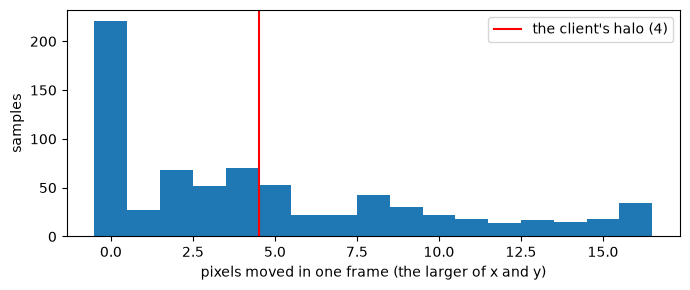

moved  0 px or less: 29.6% of 746 changed page and photo samples
moved  4 px or less: 58.7% of 746 changed page and photo samples
moved  8 px or less: 77.5% of 746 changed page and photo samples
moved 15 px or less: 95.4% of 746 changed page and photo samples


In [5]:
"""How far scrolled and panned content moves in a frame."""

scrolled = masks["changed"] & (masks.get("page", False) | masks.get("photo", False))
chosen = np.flatnonzero(scrolled)
finder = models.Shift(radius=HALO, block=None).to(DEVICE)
offsets = []
with torch.no_grad():
    for first in range(0, len(chosen), 256):
        batch = training.to_tensor(inputs[chosen[first:first + 256]])
        offsets += [finder.offsets[i] for i in finder.offsets_of(*batch.unbind(1)).flatten().tolist()]
reach = np.array([max(abs(dy), abs(dx)) for dy, dx in offsets])

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(reach, bins=np.arange(HALO + 2) - 0.5)
ax.axvline(webexport.TILE_HALO + 0.5, color="red", label=f"the client's halo ({webexport.TILE_HALO})")
ax.set_xlabel("pixels moved in one frame (the larger of x and y)")
ax.set_ylabel("samples")
ax.legend()
fig.tight_layout()
plt.show()
for limit in (0, webexport.TILE_HALO, 8, HALO - 1):
    print(f"moved {limit:2} px or less: {(reach <= limit).mean():5.1%} of {len(reach)} changed page and photo samples")

## What they look like

One changed sample of each kind, the core and its halo (the red box is what is scored).
Look at the edges: linear draws a moved edge twice, the shift methods either land it or
smear it, and nothing gets a menu that was not there yet.

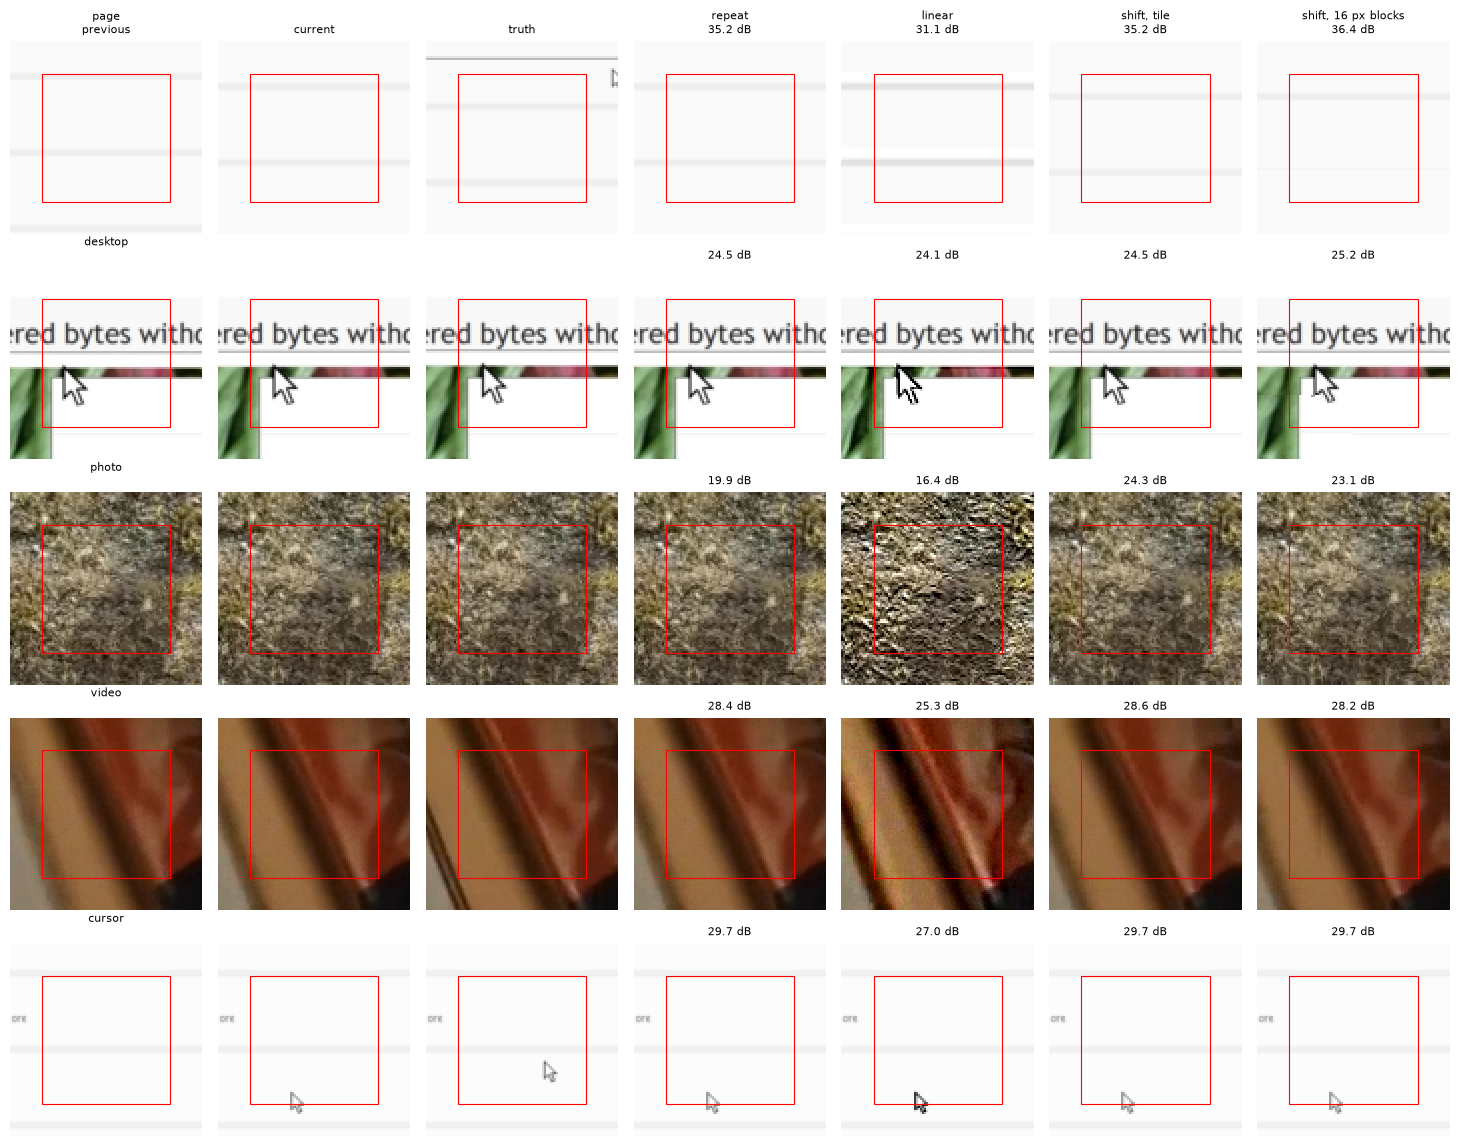

In [6]:
"""One changed sample of each kind through every method."""

show = ["repeat", "linear", "shift, tile", "shift, 16 px blocks"]
pick_rng = np.random.default_rng(SEED)
picks = [(kind, int(pick_rng.choice(np.flatnonzero(masks[f"{kind}, changed"]))))
         for kind in KINDS if masks[f"{kind}, changed"].any()]

columns = ["previous", "current", "truth", *show]
fig, axes = plt.subplots(len(picks), len(columns), figsize=(2.1 * len(columns), 2.3 * len(picks)), squeeze=False)
for row, (kind, index) in enumerate(picks):
    sample = training.to_tensor(inputs[index:index + 1])
    truth = training.to_tensor(targets[index:index + 1])
    pictures = {"previous": sample[:, 0], "current": sample[:, 1], "truth": truth}
    with torch.no_grad():
        for name in show:
            pictures[name] = METHODS[name].to(DEVICE)(sample[:, 0], sample[:, 1]).clamp(0, 1)
    for column, name in enumerate(columns):
        ax = axes[row][column]
        ax.imshow(pictures[name][0].permute(1, 2, 0).cpu().numpy(), interpolation="nearest")
        ax.add_patch(plt.Rectangle((HALO - 0.5, HALO - 0.5), manifest["core"], manifest["core"],
                                   fill=False, color="red", lw=0.8))
        title = name if row == 0 else ""
        if name in show:
            score = metrics.wpsnr(runs.trim(pictures[name], HALO), runs.trim(truth, HALO))
            title = f"{title}\n{score:.1f} dB" if title else f"{score:.1f} dB"
        if column == 0:
            title = f"{kind}\n{title}"
        ax.set_title(title, fontsize=8)
        ax.axis("off")
fig.tight_layout()
plt.show()

## Speed

Each method in torch on this computer's GPU, one stream frame at a time - the stream is
640x360 to 1920x1080 depending on what the client asked for. The tile method on a whole
frame finds one offset for all of it, which is not what it would do per tile; it is timed
only to show what the search costs. At a radius of 16 the search is 1089 offsets, each a few
small torch calls, so its time here is mostly launching them and hardly grows with the
frame: it says the search is not free, not what a fused kernel would cost.

In [7]:
"""torch, one frame at a time."""

speed_ms = {}
for width, height in BENCH_SIZES:
    previous, current = torch.rand(2, 1, 3, height, width, device=DEVICE)
    with torch.no_grad():
        speed_ms[width, height] = {name: speed.time_ms(lambda m=method: m(previous, current), seconds=0.3)
                                   for name, method in METHODS.items()}

print(f"{'frame':>11}" + "".join(f"{name.replace('shift, ', ''):>16}" for name in METHODS))
for (width, height), row in speed_ms.items():
    print(f"{f'{width}x{height}':>11}" + "".join(f"{row[name]:16.2f}" for name in METHODS))
print("ms per frame")

      frame          repeat          linear       half step            tile    16 px blocks     8 px blocks
    640x360            0.00            0.09            0.04           63.49          144.57          132.34
    960x540            0.00            0.08            0.08          115.14           93.06          101.81
   1280x720            0.00            0.14            0.14           73.77          102.62           80.09
  1920x1080            0.00            0.30            0.30           82.13          290.54          135.72
ms per frame


## The bar to beat

In [8]:
changed = {name: scores["changed"] for name, scores in results.items()}
best = max(changed, key=lambda name: changed[name]["ssim"])
print(f"quality: {best} at {changed[best]['ssim']:.4f} SSIM-Y, {changed[best]['wpsnr']:.2f} dB on the "
      f"{masks['changed'].sum()} changed samples (repeat {changed['repeat']['ssim']:.4f}, "
      f"{changed['repeat']['wpsnr']:.2f} dB; linear {changed['linear']['ssim']:.4f}, {changed['linear']['wpsnr']:.2f} dB)")
print(f"speed:   at 960x540, repeat costs {speed_ms[960, 540]['repeat']:.2f} ms, linear "
      f"{speed_ms[960, 540]['linear']:.2f} ms and {best} {speed_ms[960, 540][best]:.2f} ms (torch)")

quality: shift, tile at 0.8230 SSIM-Y, 32.26 dB on the 1852 changed samples (repeat 0.7312, 27.21 dB; linear 0.6728, 24.74 dB)
speed:   at 960x540, repeat costs 0.00 ms, linear 0.08 ms and shift, tile 115.14 ms (torch)


## Export to ONNX for the client

The client runs `extrapolate.onnx` on 328x188 tiles (a 320x180 step and a halo of 4) with
two inputs, `previous` and `current`. Repeat and the two blends are a few elementwise
operators, so they export as they are, and replacing the mock is copying one over it. The
shift methods do not: their search is (2r+1)^2 shifted copies of the picture and a
comparison each, which a learned model would have to find another way.

In [9]:
"""Export repeat, linear and half step at the client's tile, and time them on the desktop CPU."""

EXPORTABLE = {"repeat": "static repeat", "linear": "static linear (the mock)", "half step": "static half step"}

step_h, step_w = webexport.TILE_STEP
for name, label in EXPORTABLE.items():
    module = METHODS[name].cpu()
    filename = f"extrapolate_static_{name.replace(' ', '_')}_tile{step_w}x{step_h}.onnx"
    info = webexport.export(module, filename, webexport.TILE_INPUT, label=label)
    example = np.random.rand(2, 1, 3, *webexport.TILE_INPUT).astype(np.float32)
    webexport.check_graph(info["path"], module, *example)
    ms = webexport.time_graph(info["path"], webexport.TILE_INPUT)
    webexport.annotate(info, cpu_ms=round(ms, 3))
    print(webexport.summary_line(info, ms))

print(f"\nwritten to {webexport.MODELS_DIR}")

extrapolate_static_repeat_tile320x180.onnx              0.3 KB    0.03 ms   Identityx1


extrapolate_static_linear_tile320x180.onnx              0.7 KB    0.08 ms   Addx1, Clipx1, Constantx3, Mulx1, Subx1   OUTSIDE BUDGET: Clip, Mul, Sub


extrapolate_static_half_step_tile320x180.onnx           0.7 KB    0.30 ms   Addx1, Clipx1, Constantx3, Mulx1, Subx1   OUTSIDE BUDGET: Clip, Mul, Sub

written to /home/henrik/desktop-streamer-ai/dist/frame_gen_extra
